# KerSplit: factoring polynomials over $\mathbb{Z}_p$ with Berlekamp's algorithm

CS5610 Computational Number Theory and Algebra, IIT Hyderabad, 2026. Project topic 19.

**Problem.** Given a prime $p$ and $f \in \mathbb{Z}_p[x]$, find
$f = c \cdot h_1^{e_1} \cdots h_k^{e_k}$ with distinct monic irreducible $h_i$.

**Idea in one line.** For square-free $f$, the polynomials $g$ with $g^p \equiv g \pmod f$ form a
vector space whose dimension is the number of irreducible factors; it is the kernel of a matrix
$Q - I$, and gcds of $f$ with its elements split $f$.

**The pipeline, one section of this notebook per step:**

| Step | What happens | Code | Owner |
|---|---|---|---|
| 0 | split $f$ into square-free parts, with multiplicities | `squarefree.py` | Member 1 |
| 1 | build the $d \times d$ matrix $Q$, row $i$ = $x^{ip} \bmod f$ | `qmatrix.py` | Member 1 |
| 2 | kernel of $Q - I$ by Gaussian elimination: basis of $B$, $\dim B = r$ | `kernel.py` | Member 2 |
| 3 | small $p$: $f = \prod_{s \in \mathbb{Z}_p} \gcd(f, g - s)$ | `berlekamp.py` | Member 2 |
| 4 | large $p$: $\gcd(f, g^{(p-1)/2} - 1)$ for random $g \in B$ | `random_split.py` | Member 3 |
| 5 | correctness against Sage and timing against our HW3 Cantor-Zassenhaus | `tests/`, `bench/` | Member 3 |

All algorithm code lives in the `kersplit/` package; this notebook only calls it. Sage supplies
arithmetic in $\mathbb{Z}_p[x]$ (`+ - * % gcd`) and is used as an answer key, nothing more.

In [1]:
import random
import time

from IPython.display import Image, Markdown, display
import ipywidgets as widgets
from sage.all import GF, PolynomialRing, matrix, previous_prime

from kersplit import (berlekamp_basis, berlekamp_matrix, factor, split_deterministic,
                      squarefree_decomposition)
from kersplit.kernel import left_kernel_basis
from kersplit.polyio import parse_problem, parse_polynomial
from kersplit.random_split import split_once


def ring(p):
    R = PolynomialRing(GF(p), 'x')
    return R, R.gen()


def agrees_with_sage(f, result):
    expected = f.factor()
    return result.unit == expected.unit() and sorted(result.factors) == sorted(expected)

## The input format

Same as Programming HW3: the prime, the degree, and the polynomial. The command line version is
`python -m kersplit --trace < examples/x4plus1_mod3.txt`.

In [2]:
text = open('examples/x4plus1_mod3.txt').read()
print(text)
problem = parse_problem(text)
print('parsed: p =', problem.p, ' f =', problem.f)

p:3
d:4
f:x^4 + 1

parsed: p = 3  f = x^4 + 1


## Step 0. Square-free decomposition (Member 1)

Berlekamp's argument needs $f$ square-free (no repeated factor), so we first write
$f = \prod_e g_e^{\,e}$ where each $g_e$ is square-free.

* Over any field, $\gcd(f, f')$ contains every repeated factor, so $f / \gcd(f, f')$ is square-free.
* **The characteristic-$p$ trap.** If $h^p \mid f$, then $(h^p)' = p\,h^{p-1}h' = 0$. A polynomial
  with zero derivative only has the powers $x^0, x^p, x^{2p}, \dots$, so it equals $u(x)^p$ for
  $u = \sum a_{ip}\, x^{i}$ (in $\mathbb{Z}_p$, $a^p = a$; notes, Claim 12). We take that $p$-th root
  and recurse, multiplying the multiplicities by $p$.

Below, $(x^2+1)^3$ over $\mathbb{Z}_3$ has derivative zero, so the textbook formula alone would
miss it entirely.

In [3]:
R, x = ring(3)
f = (x**2 + 1)**3
print('f  =', f)
print("f' =", f.derivative())
print('square-free decomposition:', squarefree_decomposition(f))

f  = x^6 + 1
f' = 0
square-free decomposition: [(x^2 + 1, 3)]


A mixed example over $\mathbb{Z}_5$: multiplicity 5 needs the $p$-th root, multiplicities 1 and 2
come from the gcd loop. The last line rebuilds $f$ from the pieces.

In [4]:
R, x = ring(5)
f = (x + 1)**5 * (x**2 + 2)**2 * (x + 3)
parts = squarefree_decomposition(f)
for g, e in parts:
    print(f'multiplicity {e}: {g}')
print('product of g^e equals f:', R.prod(g**e for g, e in parts) == f)

multiplicity 1: x + 3
multiplicity 2: x^2 + 2
multiplicity 5: x + 1
product of g^e equals f: True


## Step 1. The Berlekamp matrix $Q$ (Member 1)

From now on $f$ is square-free of degree $d$. Polynomials of degree $< d$ are vectors in
$\mathbb{Z}_p^d$ (coefficients of $1, x, \dots, x^{d-1}$).

The map $g \mapsto g^p \bmod f$ is **linear** over $\mathbb{Z}_p$: $(a + b)^p = a^p + b^p$ in
characteristic $p$, and $c^p = c$ for $c \in \mathbb{Z}_p$. So it is a $d \times d$ matrix $Q$ whose
row $i$ holds the coefficients of $x^{ip} \bmod f$.

We compute $x^p \bmod f$ once by repeated squaring ($O(\log p)$ multiplications), then each
next row is the previous one times $x^p$, reduced mod $f$.

In [5]:
R, x = ring(3)
f = x**4 + 1
Q = berlekamp_matrix(f)
print(Q)
print()
for i in range(4):
    print(f'row {i}: x^{3 * i} mod f = {(x**(3 * i)) % f}')

[1 0 0 0]
[0 0 0 1]
[0 0 2 0]
[0 1 0 0]

row 0: x^0 mod f = 1
row 1: x^3 mod f = x^3
row 2: x^6 mod f = 2*x^2
row 3: x^9 mod f = x


## Step 2. The kernel of $Q - I$ counts the factors (Member 2)

Let $B = \{\, g : g^p \equiv g \pmod f \,\}$, the *Berlekamp subalgebra*. In matrix form,
$g \in B \iff v_g\,(Q - I) = 0$, so $B$ is the left kernel of $Q - I$.

**Theorem.** If $f = h_1 \cdots h_r$ is square-free with distinct irreducible $h_i$, then
$\dim B = r$.

*Proof sketch.* By the CRT (notes, Theorem 13),
$\mathbb{Z}_p[x]/(f) \cong \mathbb{Z}_p[x]/(h_1) \times \cdots \times \mathbb{Z}_p[x]/(h_r)$,
and each factor on the right is a field. In a field, $t^p = t$ has exactly the $p$ roots
$\mathbb{Z}_p$ (Fermat). So $g \in B$ exactly when $g \equiv s_i \pmod{h_i}$ for constants
$s_i \in \mathbb{Z}_p$; there are $p^r$ such $g$, so $\dim B = r$. $\square$

We compute the kernel with our own Gauss-Jordan elimination over $\mathbb{Z}_p$ (`kernel.py`). The
constant $1$ is always in $B$, so $r = 1$ means $f$ is irreducible.

In [6]:
basis = berlekamp_basis(f, Q)
print('basis of B:', basis, '  ->  r =', len(basis))
M = Q - matrix.identity(GF(3), 4)
vectors = left_kernel_basis(M)
print('each v satisfies v (Q - I) = 0:', all(not any(matrix(GF(3), [v]) * M) for v in vectors))
print('same dimension as Sage left_kernel():', len(vectors) == M.left_kernel().dimension())

basis of B: [1, x^3 + x]   ->  r = 2
each v satisfies v (Q - I) = 0: True
same dimension as Sage left_kernel(): True


$x^4 + 1$ is irreducible over $\mathbb{Z}$, yet modulo every prime it splits. The kernel tells
us how many pieces before we find any of them. Modulo 17 it splits into 4 linear factors
because $17 \equiv 1 \pmod 8$, so $\mathbb{Z}_{17}$ contains the 8th roots of unity.

In [7]:
for p in [3, 5, 7, 11, 13, 17, 19, 23]:
    R, x = ring(p)
    f = x**4 + 1
    print(f'p = {p:2}:  r = {len(berlekamp_basis(f))}   {factor(f)}')

p =  3:  r = 2   (x^2 + x + 2) * (x^2 + 2*x + 2)
p =  5:  r = 2   (x^2 + 2) * (x^2 + 3)
p =  7:  r = 2   (x^2 + 3*x + 1) * (x^2 + 4*x + 1)
p = 11:  r = 2   (x^2 + 3*x + 10) * (x^2 + 8*x + 10)
p = 13:  r = 2   (x^2 + 5) * (x^2 + 8)
p = 17:  r = 4   (x + 2) * (x + 8) * (x + 9) * (x + 15)
p = 19:  r = 2   (x^2 + 6*x + 18) * (x^2 + 13*x + 18)
p = 23:  r = 2   (x^2 + 5*x + 1) * (x^2 + 18*x + 1)


## Step 3. The deterministic split (Member 2)

Over $\mathbb{Z}_p$, $t^p - t = \prod_{s \in \mathbb{Z}_p} (t - s)$. For $g \in B$, $f$ divides
$g^p - g = \prod_s (g - s)$, and the factors $g - s$ are pairwise coprime, so

$$f = \prod_{s \in \mathbb{Z}_p} \gcd(f,\; g - s).$$

$\gcd(f, g - s)$ collects exactly the $h_i$ with $g \equiv s \pmod{h_i}$. A non-constant $g$
separates at least two factors; if one $g$ does not separate all of them we refine the pieces
with the next basis element. Any two factors are separated by some basis element, so after the
whole basis all $r$ factors are found.

**Cost:** up to $p$ gcds per split, so the running time is polynomial in $d$ and $p$, **not in
$\log p$**. That is fine for $p = 3$ and impossible for a 512-bit $p$.

In [8]:
R, x = ring(3)
factor(x**4 + 1, method='deterministic', trace=True);

f = x^4 + 1 over Z_3, degree 4
square-free part with multiplicity 1: x^4 + 1
  Q (row i = x^(ip) mod f):
    [1 0 0 0]
    [0 0 0 1]
    [0 0 2 0]
    [0 1 0 0]
  kernel of Q - I: basis {1, x^3 + x} -> r = 2
  split with g = x^3 + x
    piece x^4 + 1:
      s = 1: gcd = x^2 + 2*x + 2
      s = 2: gcd = x^2 + x + 2
result: (x^2 + x + 2) * (x^2 + 2*x + 2)


A case where one basis element cannot be enough: $r = 4$ factors over $\mathbb{Z}_2$, but $g$
takes only $p = 2$ values, so one $g$ makes at most 2 pieces. The second basis element refines
each piece.

In [9]:
R, x = ring(2)
f = x * (x + 1) * (x**2 + x + 1) * (x**3 + x + 1)
result = factor(f, method='deterministic', trace=True)
print('agrees with Sage factor():', agrees_with_sage(f, result))

f = x^7 + x^5 + x^2 + x over Z_2, degree 7
square-free part with multiplicity 1: x^7 + x^5 + x^2 + x
  Q (row i = x^(ip) mod f):
    [1 0 0 0 0 0 0]
    [0 0 1 0 0 0 0]
    [0 0 0 0 1 0 0]
    [0 0 0 0 0 0 1]
    [0 0 1 1 0 0 1]
    [0 0 1 1 1 1 1]
    [0 1 0 1 1 0 0]
  kernel of Q - I: basis {1, x^4 + x^3 + x^2, x^5 + x^3 + x^2, x^6 + x^3 + x^2 + x} -> r = 4
  split with g = x^4 + x^3 + x^2
    piece x^7 + x^5 + x^2 + x:
      s = 0: gcd = x^3 + x^2 + x
      s = 1: gcd = x^4 + x^3 + x^2 + 1
  split with g = x^5 + x^3 + x^2
    piece x^3 + x^2 + x:
      s = 0: gcd = x
      s = 1: gcd = x^2 + x + 1
    piece x^4 + x^3 + x^2 + 1:
      s = 0: gcd = x^3 + x + 1
      s = 1: gcd = x + 1
result: x * (x + 1) * (x^2 + x + 1) * (x^3 + x + 1)
agrees with Sage factor(): True


## Step 4. Large $p$: the randomized split (Member 3)

Pick $g = c_1 b_1 + \dots + c_r b_r \in B$ with random $c_j \in \mathbb{Z}_p$. Modulo each $h_i$,
$g$ is a uniformly random constant $s_i$, independently for different $i$ (CRT again).

By Euler's criterion, $s^{(p-1)/2} = 1$ exactly when $s$ is a non-zero square, which happens for
$(p-1)/2$ of the $p$ values. So each $h_i$ divides $\gcd(f, g^{(p-1)/2} - 1)$ independently with
probability $\frac{p-1}{2p} \approx \frac12$, and the gcd is a proper factor unless all $h_i$ land on
the same side: the same coin-flip argument as Cantor-Zassenhaus (notes, Claim 14).
For $p = 2$ the constants are $0$ or $1$, so we use $\gcd(f, g)$ directly.

Each try costs one exponentiation, $O(\log p)$ multiplications, so the whole algorithm is
polynomial in $d$ and $\log p$ (in expectation).

**Checking the 1/2 claim.** For $f = h_1 h_2$ the gcd splits $f$ when exactly one of the two coins
comes up heads: probability $2q(1-q)$ with $q = \frac{p-1}{2p}$.

In [10]:
p = 101
R, x = ring(p)
f = (x**3 + x + 1) * (x**2 + 2)
b = berlekamp_basis(f)
rng = random.Random(0)
trials = 2000
splits = 0
for _ in range(trials):
    g = sum(rng.randrange(p) * bj for bj in b)
    splits += len(split_once(f, g, p)) == 2
q = (p - 1) / (2 * p)
print(f'observed split rate {splits / trials:.3f}, predicted {2 * q * (1 - q):.3f}')

observed split rate 0.496, predicted 0.500


HW3 sample 2 ($p = 987013$, degree 24), which is too large for the deterministic split:

In [11]:
problem = parse_problem(open('examples/hw3_sample2.txt').read())
result = factor(problem.f, method='random', trace=True)
print('agrees with Sage factor():', agrees_with_sage(problem.f, result))

f = x^24 + 90470*x^23 + 584910*x^22 + 424214*x^21 + 617809*x^20 + 564069*x^19 + 498745*x^18 + 585592*x^17 + 948174*x^16 + 401092*x^15 + 969584*x^14 + 205925*x^13 + 227787*x^12 + 799739*x^11 + 79152*x^10 + 206275*x^9 + 615771*x^8 + 297793*x^7 + 804341*x^6 + 601340*x^5 + 352012*x^4 + 44059*x^3 + 265844*x^2 + 982273*x + 805981 over Z_987013, degree 24
square-free part with multiplicity 1: x^24 + 90470*x^23 + 584910*x^22 + 424214*x^21 + 617809*x^20 + 564069*x^19 + 498745*x^18 + 585592*x^17 + 948174*x^16 + 401092*x^15 + 969584*x^14 + 205925*x^13 + 227787*x^12 + 799739*x^11 + 79152*x^10 + 206275*x^9 + 615771*x^8 + 297793*x^7 + 804341*x^6 + 601340*x^5 + 352012*x^4 + 44059*x^3 + 265844*x^2 + 982273*x + 805981
  Q is 24 x 24 (row i = x^(ip) mod f)
  kernel of Q - I: basis {1, x^21 + 533137*x^20 + 521220*x^19 + 213200*x^18 + 493975*x^17 + 246735*x^16 + 19917*x^15 + 244999*x^14 + 897468*x^13 + 246685*x^12 + 141075*x^11 + 477262*x^10 + 928167*x^9 + 695834*x^8 + 976864*x^7 + 417375*x^6 + 255311*x^5

$p = 2$ and a 512-bit prime, the two extremes. For the 512-bit case we print only the factor
degrees, since the coefficients have about 155 digits.

In [12]:
R, x = ring(2)
f = (x**3 + x + 1) * (x**2 + x + 1)**4 * x**3
result = factor(f, method='random')
print('p = 2:', result, '| agrees with Sage:', agrees_with_sage(f, result))

p = int(previous_prime(2**512))
R, x = ring(p)
f = (x**3 + 2*x + 7) * (x**2 + 3)**2 * (x + 12345)
start = time.perf_counter()
result = factor(f, method='random')
elapsed = time.perf_counter() - start
print(f'p has {p.bit_length()} bits: {elapsed:.3f} s, factor degrees and multiplicities',
      [(h.degree(), e) for h, e in result.factors], '| agrees with Sage:', agrees_with_sage(f, result))

p = 2: x^3 * (x^2 + x + 1)^4 * (x^3 + x + 1) | agrees with Sage: True


p has 512 bits: 0.074 s, factor degrees and multiplicities [(1, 1), (1, 1), (1, 1), (1, 1), (2, 2)] | agrees with Sage: True


## Step 5. Correctness

`python -m pytest` runs 66 tests, including 500 random products of known irreducibles checked
against Sage's `factor()` for $p \in \{2, 3, 5, 7, 11, 13, 101, 987013\}$ and a 512-bit prime, with
multiplicities up to $p^2$. Here is a small live version of that check.

In [13]:
def random_case(p, rng):
    R, x = ring(p)
    f = R.one()
    for _ in range(rng.randint(1, 4)):
        f *= R.random_element(degree=rng.randint(1, 5)).monic() ** rng.randint(1, 3)
    return f


rng = random.Random(1)
cases = [random_case(p, rng) for p in [2, 3, 5, 7, 101, 987013] for _ in range(20)]
correct = sum(agrees_with_sage(f, factor(f)) for f in cases)
print(f'{correct} of {len(cases)} random polynomials factored exactly as Sage factors them')

120 of 120 random polynomials factored exactly as Sage factors them


## Results: Berlekamp vs our HW3 Cantor-Zassenhaus

Produced by `python -m bench.bench` (about 35 s) and saved in `bench/results/`; shown here
rather than re-run live. Every method in a row runs on the same random polynomials.

In [14]:
display(Markdown(open('bench/results/summary.md').read()))

# Benchmark results

Generated by `python -m bench.bench`. Each cell is the median over the same 7 random
square-free monic polynomials for every method in that row. Every output of our code was
checked against Sage `factor()`:
**378 of 378 factorizations correct.**

## Time vs degree (p = 987013)

| d | Berlekamp (randomized) | Cantor-Zassenhaus (HW3) | Sage factor() (C library) |
|---|---|---|---|
| 10 | 0.0007 | 0.0002 | 0.0001 |
| 20 | 0.0025 | 0.0004 | 0.0001 |
| 30 | 0.0065 | 0.0009 | 0.0002 |
| 40 | 0.0133 | 0.0013 | 0.0003 |
| 50 | 0.0248 | 0.0026 | 0.0006 |
| 60 | 0.0400 | 0.0032 | 0.0008 |
| 70 | 0.0633 | 0.0060 | 0.0013 |
| 80 | 0.0914 | 0.0058 | 0.0016 |
| 90 | 0.1326 | 0.0116 | 0.0023 |
| 100 | 0.1768 | 0.0105 | 0.0025 |

## Time vs size of p (d = 30)

| bits of p | Berlekamp (deterministic) | Berlekamp (randomized) | Cantor-Zassenhaus (HW3) |
|---|---|---|---|
| 2 | 0.0032 | 0.0026 | 0.0002 |
| 4 | 0.0041 | 0.0036 | 0.0002 |
| 6 | 0.0044 | 0.0041 | 0.0004 |
| 8 | 0.0053 | 0.0041 | 0.0004 |
| 10 | 0.0094 | 0.0061 | 0.0006 |
| 12 | 0.0226 | 0.0061 | 0.0008 |
| 14 | 0.0850 | 0.0061 | 0.0007 |
| 16 | 0.2420 | 0.0066 | 0.0010 |
| 32 | - | 0.0111 | 0.0025 |
| 64 | - | 0.0400 | 0.0430 |
| 128 | - | 0.0624 | 0.2144 |
| 256 | - | 0.1945 | 0.4068 |
| 512 | - | 0.7357 | 1.6839 |

Sage stores polynomials with FLINT for p < 2^63 and with NTL above, so part of the jump
between 32 and 64 bits is the library, not the algorithm. Compare methods within a row.
Deterministic Berlekamp is skipped above 16 bits: it tries all p values of s.

## Berlekamp stages (p = 987013)

| d | build Q | kernel of Q - I | randomized split |
|---|---|---|---|
| 10 | 0.0002 | 0.0003 | 0.0002 |
| 20 | 0.0005 | 0.0016 | 0.0003 |
| 30 | 0.0011 | 0.0049 | 0.0005 |
| 40 | 0.0019 | 0.0113 | 0.0005 |
| 50 | 0.0029 | 0.0213 | 0.0008 |
| 60 | 0.0040 | 0.0359 | 0.0007 |
| 70 | 0.0056 | 0.0568 | 0.0008 |
| 80 | 0.0071 | 0.0831 | 0.0013 |
| 90 | 0.0093 | 0.1169 | 0.0015 |
| 100 | 0.0112 | 0.1627 | 0.0017 |


**Time vs size of $p$.** The deterministic split grows linearly with $p$ (it loops over all
$s$), which is the "polynomial in $p$, not $\log p$" point made visible. The randomized split
barely moves. From 64 bits upward randomized Berlekamp beats our Cantor-Zassenhaus, which needs
about $d/2$ exponentiations to the power $p$ in its distinct-degree phase.

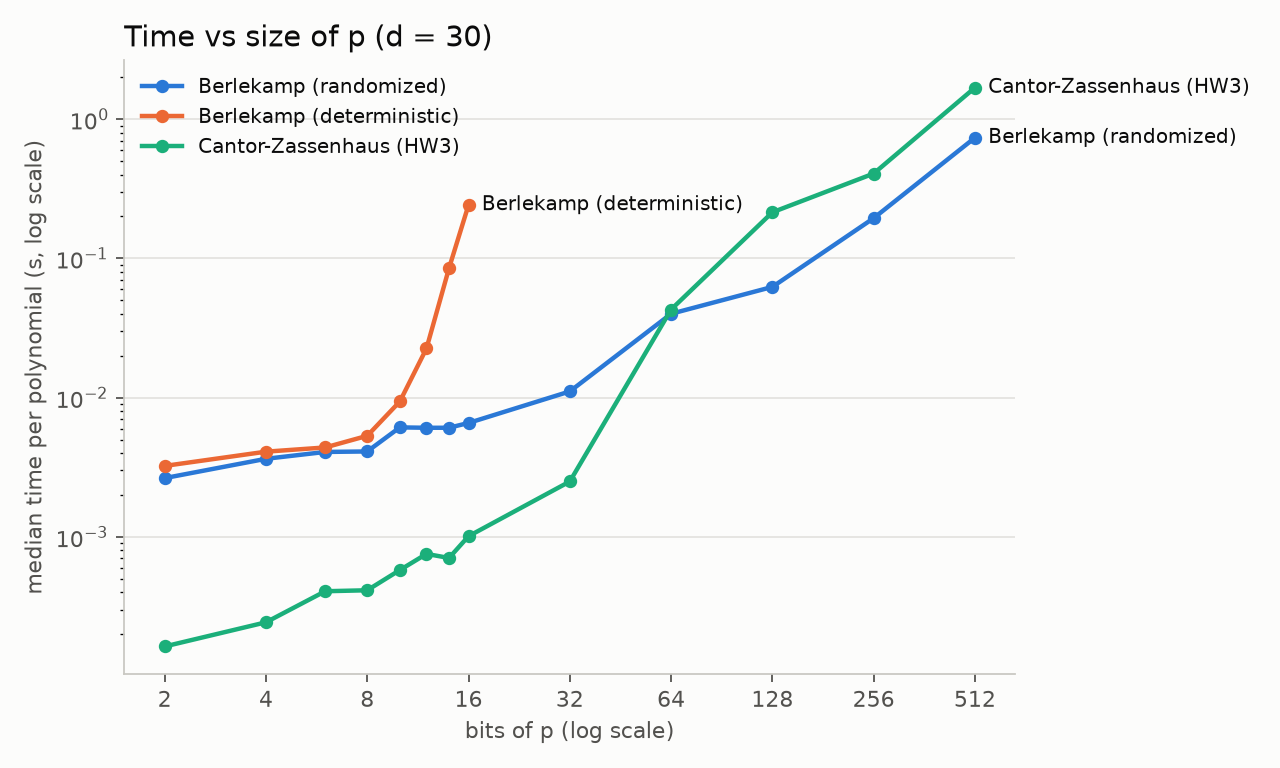

In [15]:
display(Image('bench/results/time_vs_p.png', width=720))

**Time vs degree.** At $p = 987013$ Berlekamp grows like $d^3$ because of the Gaussian
elimination; Cantor-Zassenhaus is faster here because its work is in fast C polynomial
arithmetic while our elimination is in Python.

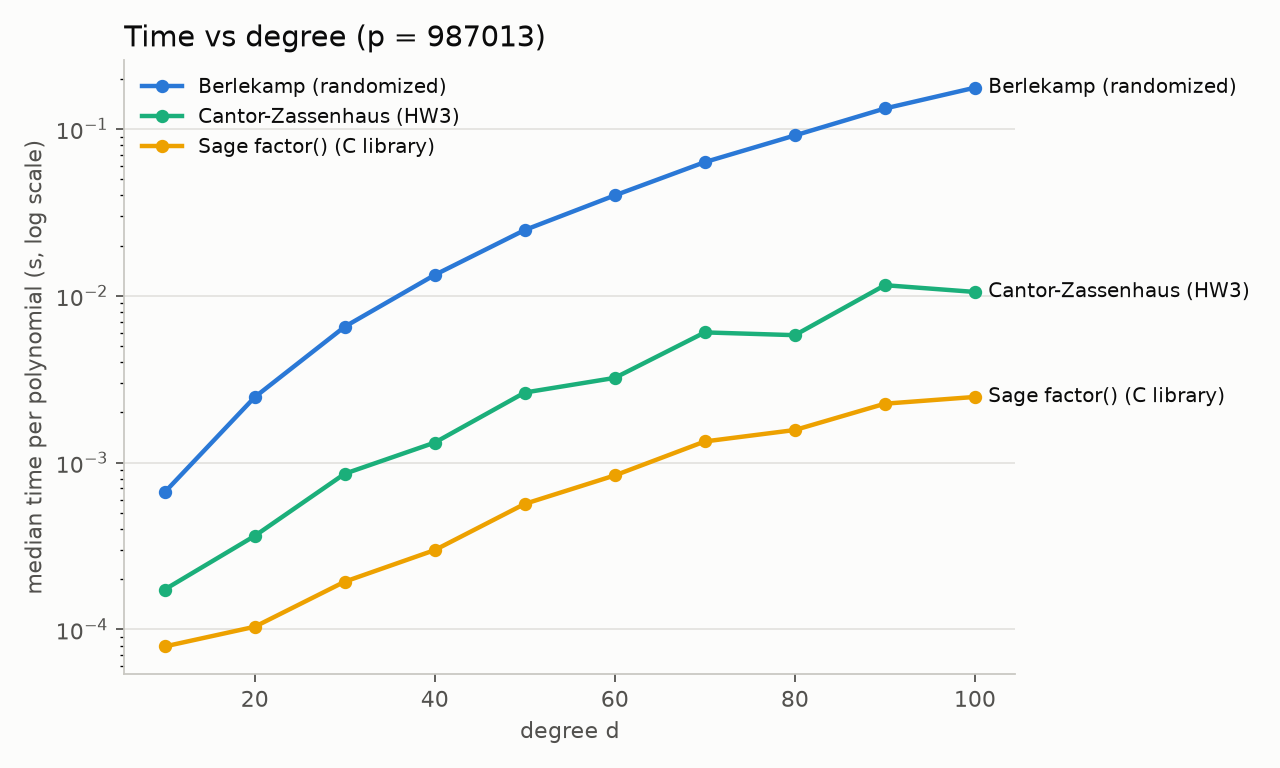

In [16]:
display(Image('bench/results/time_vs_degree.png', width=720))

**Where the time goes.** Building $Q$ and splitting are cheap; the kernel of $Q - I$ is
over 90% of the time at $d = 100$.

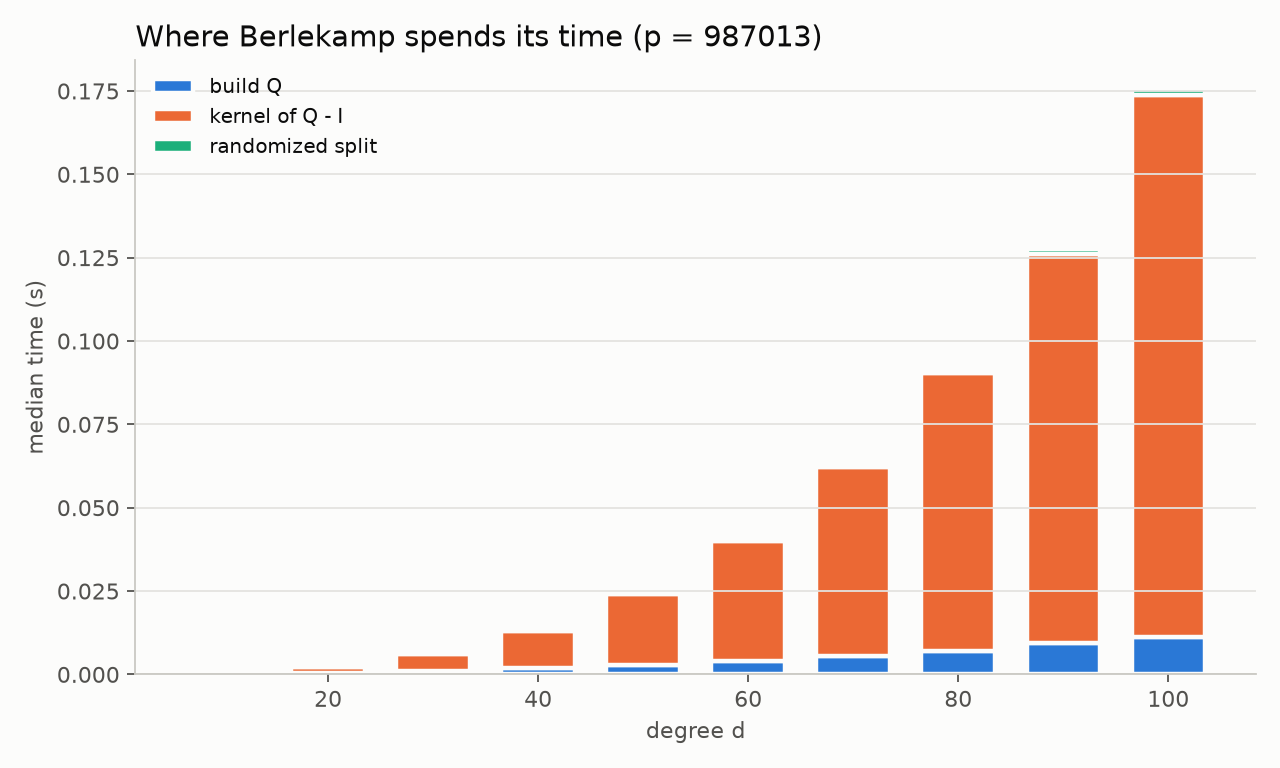

In [17]:
display(Image('bench/results/berlekamp_stages.png', width=720))

## Try it yourself

Type a prime and a polynomial (`x^4 + 1` or `x**4 + 1`), choose a method, press **Run Interact**.
`deterministic` with a large $p$ will be slow, which is the point of Step 4.

In [18]:
@widgets.interact_manual(p='3', f='x^4 + 1', method=['auto', 'deterministic', 'random'])
def run(p, f, method):
    try:
        poly = parse_polynomial(f, int(p))
        factor(poly, method=method, trace=True)
    except ValueError as error:
        print('error:', error)

interactive(children=(Text(value='3', continuous_update=False, description='p'), Text(value='x^4 + 1', continu…

## Takeaways

1. $\dim \ker(Q - I)$ is the number of irreducible factors: Berlekamp knows $r$ before finding any
   factor, and $r = 1$ is an irreducibility test.
2. Square-free reduction in characteristic $p$ needs the $p$-th root step, or factors like
   $h^p$ are lost.
3. The deterministic split is polynomial in $p$, not in $\log p$, so it does not answer the open
   question of deterministic polynomial-time factoring over $\mathbb{Z}_p$. The randomized split
   is polynomial in $\log p$ and, in our measurements, beats Cantor-Zassenhaus for $p \ge 2^{64}$.
4. The cost is the $O(d^3)$ linear algebra; fast variants (Kaltofen-Shoup, Wiedemann) attack
   exactly that step and are out of scope.